# 08 · Redes neuronales de grafos

Este notebook es un módulo de **Neural Networks 1002** y supone el [módulo 02 de Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/02-retropropagacion/) (retropropagación y la capa como producto de matrices), el [módulo 03](https://neural-networks.academy.forwardforecasting.eu/es/03-entrenar-bien-redes-profundas/) (entrenar bien: Adam, decaimiento de pesos, dropout, parada temprana) y el [módulo 09](https://neural-networks.academy.forwardforecasting.eu/es/09-transformer/) (el transformer, porque la atención sobre grafos es su prima cercana).

Las imágenes son cuadrículas y el texto es una línea. Muchísimos datos reales no son ninguna de las dos cosas: una **molécula** son átomos unidos por enlaces, una **red social o de citas** son personas o artículos unidos por vínculos, una **red de carreteras** son cruces unidos por calles, una **red eléctrica** son subestaciones unidas por líneas. Estos objetos no tienen tamaño fijo, ni un orden natural de los nodos, y la información está en *quién está conectado con quién*. Una **red neuronal de grafos** (GNN, por graph neural network) es una red diseñada exactamente para esto.

En este notebook construirás, en PyTorch puro (sin biblioteca de grafos), y ejecutarás en la CPU de un portátil:

1. la **representación** de un grafo (matriz de adyacencia, lista de aristas, atributos de los nodos) y la razón por la que un modelo para grafos debe ser **invariante a las permutaciones**;
2. el **paso de mensajes** escrito desde cero (agregar a los vecinos y luego actualizar el nodo) y comprobado contra un producto de matrices;
3. las tres capas clásicas: la **red convolucional de grafos** (GCN, graph convolutional network), **GraphSAGE** (sample and aggregate, muestrear y agregar) y la **red de atención sobre grafos** (GAT, graph attention network), más la capa **GIN** (graph isomorphism network, red de isomorfismo de grafos), que usa una suma;
4. la **clasificación de nodos** en una red generada con comunidades conocidas, frente a un modelo que ignora el grafo (un MLP, perceptrón multicapa) y una línea base de atributos (regresión logística);
5. el **suavizado excesivo** (over-smoothing) y el **aplastamiento excesivo** (over-squashing), los dos modos de fallo que aparecen al apilar muchas capas, medidos según la profundidad;
6. la **predicción a nivel de grafo** con una **lectura** (readout, agrupación) sobre un conjunto real de moléculas pequeñas (MUTAG, 188 moléculas etiquetadas por mutagenicidad), con validación cruzada de 5 particiones y las mismas dos líneas base;
7. un recorrido breve por los lugares donde las GNN se usan en producción (clima, tráfico, descubrimiento de fármacos, redes eléctricas, recomendación).

**Contenido**

1. Por qué grafos
2. Representar un grafo
3. Paso de mensajes desde cero
4. GCN, GraphSAGE, GAT y GIN
5. Clasificación de nodos: comunidades en una red
6. Profundidad: suavizado excesivo y aplastamiento excesivo
7. Tareas a nivel de grafo: moléculas y la lectura
8. Dónde se usan las GNN en producción
9. Ideas clave, ejercicios, referencias

| Se apoya en | Qué reutilizamos |
|---|---|
| [02 Red neuronal y retropropagación (1001)](https://neural-networks.academy.forwardforecasting.eu/es/02-retropropagacion/) | una capa es una transformación lineal más una no linealidad; la autodiferenciación deriva todo |
| [03 Entrenar redes profundas (1001)](https://neural-networks.academy.forwardforecasting.eu/es/03-entrenar-bien-redes-profundas/) | Adam, decaimiento de pesos, dropout, elegir la época con un conjunto de validación |
| [09 Transformer (1001)](https://neural-networks.academy.forwardforecasting.eu/es/09-transformer/) | la atención como promedio ponderado por softmax, que es el GAT de la sección 4 |

¿Nuevo en PyTorch? El [curso Python 1001, sección sobre frameworks de IA](https://python.academy.forwardforecasting.eu/es/11-frameworks-de-ia/) lo presenta. El juguete es pequeño (cientos de nodos, 188 moléculas de unos 18 átomos cada una) y todo el notebook se ejecuta en pocos minutos en una CPU con semillas aleatorias fijas. La única descarga es MUTAG (24 kB, guardada en caché en `data/`).

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/es/08_redes_neuronales_de_grafos.ipynb)

**¿Lo ejecutas en Google Colab?** Elige *Entorno de ejecución > Ejecutar todo*. La primera celda de código instala solo lo que falta (no hace falta reiniciar la sesión). Los tiempos que se muestran en este notebook se midieron en un equipo con varios núcleos; un entorno de CPU gratuito de Colab (unos 2 núcleos) puede tardar varias veces más.

In [ ]:
# Preparación: funciona en local y en Google Colab. Instala solo los paquetes que faltan.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'sklearn': 'scikit-learn',
    'torch': 'torch',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Instalando:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('ADVERTENCIA: la instalación con pip falló; se continúa. Detalle:\n' + _r.stderr[-400:])
print(f"Entorno: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os, io, time, math, random, zipfile, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

torch.set_num_threads(2)
torch.manual_seed(0); np.random.seed(0); random.seed(0)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["figure.dpi"] = 100
T_START = time.time()

## 1. Por qué grafos

Una red convolucional (módulo 05 de Neural Networks 1001) aprovecha una propiedad de las imágenes: todo píxel tiene el mismo tipo de vecindad, una ventana fija de 3 por 3 o 5 por 5, de modo que un filtro pequeño puede deslizarse por todas partes. Una red recurrente o un transformer aprovechan el orden de una secuencia. Un grafo no tiene ni cuadrícula ni orden:

* **Estructura irregular.** Un átomo tiene 1 vecino, otro tiene 4. Un usuario sigue 3 cuentas, otro 3000. Un filtro con un número fijo de pesos por vecino no se puede aplicar a eso.
* **Sin orden canónico.** Si numeramos los átomos de una molécula del 1 al 18 y luego los renumeramos en otro orden, es *la misma molécula*. Un modelo que da otra respuesta tras renumerar ha aprendido algo de nuestra contabilidad, no de la química.
* **Tamaño variable.** Una molécula de 12 átomos y otra de 40 deben pasar por la misma red.

El segundo punto es el que lo condiciona todo. Una función $f$ de los atributos de los nodos es **invariante a las permutaciones** cuando da la misma salida para cualquier renumeración de los nodos, y una función que devuelve un vector por nodo es **equivariante a las permutaciones** cuando renumerar la entrada simplemente renumera la salida de la misma manera. La receta que cumple ambas cosas es dejar que cada nodo combine los atributos de sus vecinos con una operación simétrica como una suma, una media o un máximo. Eso es el **paso de mensajes**, el tema de este notebook. Bronstein et al. (2021) muestran que las CNN, las GNN y los transformers son casos de una misma idea: respetar la simetría de los datos (véanse las referencias).

## 2. Representar un grafo

Un grafo $G = (V, E)$ es un conjunto de **nodos** $V$ (aquí $n = |V|$ de ellos, donde $|V|$ significa "el número de elementos de $V$") y un conjunto de **aristas** $E$, cada una un par de nodos. Trabajamos con grafos **no dirigidos**: una arista $i - j$ se guarda en ambos sentidos, $i \to j$ y $j \to i$. Los datos asociados:

| Objeto | Símbolo | Forma | Significado |
|---|---|---|---|
| atributos de nodos | $X$ | $n \times d$ | una fila $x_i$ por nodo (para un átomo: un vector one-hot de su elemento) |
| matriz de adyacencia | $A$ | $n \times n$ | $A_{ij} = 1$ si hay una arista entre $i$ y $j$, y $0$ en caso contrario |
| grado | $d_i$ | $n$ | número de vecinos del nodo $i$, $d_i = \sum_j A_{ij}$ |
| lista de aristas | `edge_index` | $2 \times m$ | la fila 0 contiene el nodo **origen** y la fila 1 el nodo **destino** de cada una de las $m$ aristas dirigidas |
| etiquetas | $y$ | $n$ o una por grafo | lo que queremos predecir |

La matriz de adyacencia es fácil de razonar pero desperdicia memoria: una red social de un millón de personas necesitaría $10^{12}$ celdas, casi todas cero. La **lista de aristas** guarda solo las $m$ aristas que existen y es lo que usan las bibliotecas reales. Escribiremos todo con la lista de aristas y usaremos la matriz de adyacencia solo para comprobar nuestro trabajo.

Construyamos un grafo diminuto parecido a una molécula (un anillo de seis átomos con una cadena lateral), veamos ambas representaciones y probemos numéricamente el argumento de simetría de la sección 1: la **suma de los atributos de los nodos** no cambia si renumeramos los nodos, pero una función que mira la *posición* de los nodos sí cambia.

In [2]:
# Una molécula de juguete: un anillo de 6 átomos (0..5) con una cadena de 2 átomos (6, 7) unida al átomo 0.
bonds = [(0,1),(1,2),(2,3),(3,4),(4,5),(5,0),(0,6),(6,7)]
n = 8
src = [a for a, b in bonds] + [b for a, b in bonds]      # en ambos sentidos
dst = [b for a, b in bonds] + [a for a, b in bonds]
edge_index = torch.tensor([src, dst])                    # forma 2 x m, con m = 16 aristas dirigidas
A = torch.zeros(n, n); A[edge_index[0], edge_index[1]] = 1
elements = ["C","C","C","C","C","C","N","O"]
X = torch.tensor([[e == s for s in ["C","N","O"]] for e in elements], dtype=torch.float32)
print("edge_index (lista de aristas):\n", edge_index)
print("grados:", A.sum(1).int().tolist())
print("adyacencia simétrica:", bool((A == A.T).all()))

# renumeramos los nodos con una permutación aleatoria P: atributos X -> X[perm], adyacencia A -> A[perm][:, perm]
perm = torch.randperm(n)
X_p, A_p = X[perm], A[perm][:, perm]
print("suma de atributos de nodos, original   :", X.sum(0).tolist())
print("suma de atributos de nodos, renumerado :", X_p.sum(0).tolist(), "(idéntica: invariante a permutaciones)")
print("atributos de la fila en la posición 6 (el átomo de nitrógeno), original frente a renumerado:", X[6].tolist(), X_p[6].tolist(), "(leer por posición difiere: no es invariante)")

edge_index (lista de aristas):
 tensor([[0, 1, 2, 3, 4, 5, 0, 6, 1, 2, 3, 4, 5, 0, 6, 7],
        [1, 2, 3, 4, 5, 0, 6, 7, 0, 1, 2, 3, 4, 5, 0, 6]])
grados: [3, 2, 2, 2, 2, 2, 2, 1]
adyacencia simétrica: True
suma de atributos de nodos, original   : [6.0, 1.0, 1.0]
suma de atributos de nodos, renumerado : [6.0, 1.0, 1.0] (idéntica: invariante a permutaciones)
atributos de la fila en la posición 6 (el átomo de nitrógeno), original frente a renumerado: [0.0, 1.0, 0.0] [1.0, 0.0, 0.0] (leer por posición difiere: no es invariante)


## 3. Paso de mensajes desde cero

Gilmer et al. (2017) mostraron que la mayoría de las redes de grafos encajan en una plantilla. Cada capa hace, para cada nodo $i$ a la vez:

1. **Mensaje.** Cada vecino $j$ envía un vector calculado a partir de sus atributos actuales: $m_{j \to i} = \phi(h_j)$, donde $h_j$ es el **vector oculto** (embedding) actual del nodo $j$ y $\phi$ es una función aprendida, aquí una transformación lineal $W h_j$.
2. **Agregación.** El nodo $i$ combina los mensajes recibidos con una operación simétrica: $a_i = \bigoplus_{j \in \mathcal{N}(i)} m_{j \to i}$, donde $\mathcal{N}(i)$ es el conjunto de vecinos de $i$ y $\bigoplus$ es una suma, una media o un máximo. Como la operación no depende del orden, la capa es equivariante a las permutaciones.
3. **Actualización.** El nodo mezcla el agregado con su propio estado: $h_i' = \sigma(\psi(h_i, a_i))$, donde $\psi$ es una función aprendida y $\sigma$ una no linealidad como ReLU.

Tras $k$ capas, el vector del nodo $i$ depende de todos los nodos a $k$ saltos o menos, su **campo receptivo**, el análogo en grafos del campo receptivo de una CNN. A continuación, la primera versión es un bucle lento de Python que refleja la descripción palabra por palabra, la segunda es la versión vectorizada que usa el resto del notebook (`index_add_` suma cada mensaje en la fila de su nodo destino), y las comprobamos contra el producto de matrices $A\,H$, que para una agregación por suma es exactamente "para cada nodo, suma los atributos de sus vecinos".

In [3]:
def aggregate(msgs, dst, n, kind="sum"):
    # Combina el mensaje de cada arista en la fila de su nodo destino.
    out = torch.zeros(n, msgs.shape[1])
    if kind in ("sum", "mean"):
        out = out.index_add(0, dst, msgs)
        if kind == "mean":
            deg = torch.zeros(n).index_add(0, dst, torch.ones(len(dst))).clamp(min=1)
            out = out / deg[:, None]
    elif kind == "max":
        out = out.scatter_reduce(0, dst[:, None].expand_as(msgs), msgs, "amax", include_self=False)
    return out

def mp_loop(H, edge_index):
    # la versión de libro de texto: para cada nodo, recorre a sus vecinos y suma sus mensajes
    n = H.shape[0]
    out = torch.zeros_like(H)
    for i in range(n):
        for s, d in edge_index.T.tolist():
            if d == i:
                out[i] += H[s]            # mensaje = atributos del vecino, agregación = suma
    return out

H = torch.randn(n, 4)
a_loop = mp_loop(H, edge_index)
a_vec = aggregate(H[edge_index[0]], edge_index[1], n, "sum")
a_mat = A @ H
print("bucle == vectorizada:", torch.allclose(a_loop, a_vec, atol=1e-6), "| vectorizada == A @ H:", torch.allclose(a_vec, a_mat, atol=1e-6))

# medimos el tiempo en un grafo aleatorio mayor para ver por qué vectorizamos
big_n, big_m = 2000, 20000
ei_big = torch.randint(0, big_n, (2, big_m)); H_big = torch.randn(big_n, 16)
t0 = time.time(); [aggregate(H_big[ei_big[0]], ei_big[1], big_n) for _ in range(5)]; t_vec5 = (time.time() - t0) / 5
print(f"agregación vectorizada con {big_n} nodos / {big_m} aristas: {t_vec5*1000:.2f} ms (un bucle de Python sobre nodos y aristas tardaría minutos)")

# equivarianza a permutaciones de la agregación: renumerar la entrada renumera la salida
inv = torch.argsort(perm)                      # el índice nuevo del nodo antiguo i es inv[i]
ei_perm = inv[edge_index]
agg_perm = aggregate(H[perm][ei_perm[0]], ei_perm[1], n)
print("equivariante (agregación del grafo renumerado == agregación renumerada):", torch.allclose(agg_perm, a_vec[perm], atol=1e-6))

bucle == vectorizada: True | vectorizada == A @ H: True
agregación vectorizada con 2000 nodos / 20000 aristas: 13.47 ms (un bucle de Python sobre nodos y aristas tardaría minutos)
equivariante (agregación del grafo renumerado == agregación renumerada): True


**Lectura.** El bucle, la versión vectorizada y el producto de matrices coinciden hasta el error de redondeo, así que "paso de mensajes con una suma" no tiene misterio: es $A H$. La versión vectorizada cuesta de milisegundos a unas pocas decenas de milisegundos para 2000 nodos y 20000 aristas, y escala con el número de aristas, no con $n^2$. La última línea comprueba la afirmación de simetría de la sección 1: renumerar los nodos de la entrada renumera las filas de la salida y no cambia nada más.

Todo lo que distingue a GCN, GraphSAGE, GAT y GIN es una elección de *qué es el mensaje* y *cómo se ponderan los vecinos*.

## 4. GCN, GraphSAGE, GAT y GIN

Implementamos cuatro capas con la misma interfaz `layer(h, edge_index) -> nuevo h`, cada una en pocas líneas, y usamos $\ell$ para el índice de una capa. Sea $W$ una matriz de pesos aprendida (cada capa tiene la suya).

**GCN** (Kipf y Welling, 2017). Se añade un autobucle (self-loop) a cada nodo, para que un nodo también se escuche a sí mismo, y se promedia a los vecinos con pesos que dependen de ambos grados:

$$h_i' = \sigma\Big(\sum_{j \in \mathcal{N}(i)\cup\{i\}} \frac{1}{\sqrt{d_i d_j}}\, W h_j\Big), \qquad \text{en forma matricial } H' = \sigma(\hat A H W),\quad \hat A = D^{-1/2}(A+I)D^{-1/2},$$

donde $D$ es la matriz diagonal de grados (contando el autobucle). El factor $1/\sqrt{d_i d_j}$ evita que dominen los nodos de grado alto. Es una ponderación *fija*, decidida solo por el grafo.

**GraphSAGE** (Hamilton et al., 2017). Mantiene separados el vector propio del nodo y el agregado de sus vecinos, cada uno con sus pesos: $h_i' = \sigma(W_1 h_i + W_2\, \mathrm{mean}_{j \in \mathcal{N}(i)} h_j)$. Separar "yo" de "mis vecinos" importa cuando un nodo es distinto de sus vecinos. (El artículo original además *muestrea* un número fijo de vecinos por nodo para que quepan grafos enormes en memoria; nosotros usamos todos los vecinos porque los nuestros son pequeños.)

**GAT** (Velickovic et al., 2018). Deja que la red *aprenda* el peso de cada vecino. Para la arista $j \to i$ se calcula una puntuación $e_{ij} = \mathrm{LeakyReLU}(a_{\text{src}}^\top W h_j + a_{\text{dst}}^\top W h_i)$ (con $a_{\text{src}}, a_{\text{dst}}$ vectores aprendidos), se normaliza sobre los vecinos de $i$ con un softmax, $\alpha_{ij} = \mathrm{softmax}_j(e_{ij})$, y se toma la suma ponderada $h_i' = \sigma(\sum_j \alpha_{ij} W h_j)$. Usamos varias **cabezas** (copias independientes cuyas salidas se concatenan), como en el transformer.

**GIN** (Xu et al., 2019). Una suma con un MLP pequeño: $h_i' = \mathrm{MLP}\big((1+\varepsilon)\,h_i + \sum_{j \in \mathcal{N}(i)} h_j\big)$, con $\varepsilon$ un escalar aprendido. Las sumas, a diferencia de las medias y los máximos, distinguen un nodo con dos vecinos idénticos de uno con un único vecino, lo que hace a GIN tan discriminativa como el test de Weisfeiler-Leman (un algoritmo clásico para distinguir grafos), el límite teórico de esta familia.

**Conexión con el transformer.** En el módulo 09 de Neural Networks 1001, la atención da a cada token un promedio ponderado por softmax de los valores de *todos* los demás tokens. GAT es el mismo cálculo restringido a los vecinos: un transformer es un GAT sobre el grafo completo en el que cada token está conectado con todos los demás (y donde la puntuación es un producto escalar escalado en lugar de la puntuación aditiva de arriba). Verificamos esa afirmación en el código: una atención densa con una máscara de adyacencia da exactamente el resultado del softmax sobre la lista de aristas.

In [4]:
def add_self_loops(ei, n):
    loops = torch.arange(n)
    return torch.stack([torch.cat([ei[0], loops]), torch.cat([ei[1], loops])])

class GCNLayer(nn.Module):
    def __init__(self, din, dout):
        super().__init__(); self.lin = nn.Linear(din, dout, bias=False); self.bias = nn.Parameter(torch.zeros(dout))
    def forward(self, h, ei):
        n = h.shape[0]
        ei = add_self_loops(ei, n)
        deg = torch.zeros(n).index_add(0, ei[1], torch.ones(ei.shape[1]))
        w = (deg[ei[0]] * deg[ei[1]]).rsqrt()                      # 1 / sqrt(d_i d_j) por arista
        return aggregate(self.lin(h)[ei[0]] * w[:, None], ei[1], n, "sum") + self.bias

class SAGELayer(nn.Module):
    def __init__(self, din, dout):
        super().__init__(); self.self_lin = nn.Linear(din, dout); self.nb_lin = nn.Linear(din, dout, bias=False)
    def forward(self, h, ei):
        nb = aggregate(h[ei[0]], ei[1], h.shape[0], "mean")
        return self.self_lin(h) + self.nb_lin(nb)

class GATLayer(nn.Module):
    def __init__(self, din, dout, heads=4):
        super().__init__()
        assert dout % heads == 0
        self.heads, self.dh = heads, dout // heads
        self.lin = nn.Linear(din, dout, bias=False)
        self.a_src = nn.Parameter(torch.randn(heads, self.dh) * 0.1)
        self.a_dst = nn.Parameter(torch.randn(heads, self.dh) * 0.1)
        self.bias = nn.Parameter(torch.zeros(dout))
        self.last_alpha = None
    def forward(self, h, ei):
        n = h.shape[0]
        ei = add_self_loops(ei, n)
        z = self.lin(h).view(n, self.heads, self.dh)
        e = F.leaky_relu((z * self.a_src).sum(-1)[ei[0]] + (z * self.a_dst).sum(-1)[ei[1]], 0.2)   # (m, heads)
        mx = torch.full((n, self.heads), -1e9).scatter_reduce(0, ei[1][:, None].expand_as(e), e, "amax", include_self=True)
        ex = (e - mx[ei[1]]).exp()                                                                   # softmax sobre las aristas entrantes de cada nodo
        den = torch.zeros(n, self.heads).index_add(0, ei[1], ex)
        alpha = ex / den[ei[1]]
        self.last_alpha = alpha.detach()
        out = torch.zeros(n, self.heads, self.dh).index_add(0, ei[1], alpha[:, :, None] * z[ei[0]])
        return out.reshape(n, -1) + self.bias

class GINLayer(nn.Module):
    def __init__(self, din, dout):
        super().__init__()
        self.eps = nn.Parameter(torch.zeros(1))
        self.mlp = nn.Sequential(nn.Linear(din, dout), nn.ReLU(), nn.Linear(dout, dout))
    def forward(self, h, ei):
        return self.mlp((1 + self.eps) * h + aggregate(h[ei[0]], ei[1], h.shape[0], "sum"))

class NoGraphLayer(nn.Module):
    # misma interfaz pero ignora las aristas: apilarlas da un MLP corriente aplicado a cada nodo
    def __init__(self, din, dout):
        super().__init__(); self.lin = nn.Linear(din, dout)
    def forward(self, h, ei):
        return self.lin(h)

# comprobación 1: nuestra capa GCN es igual a la fórmula matricial  A_hat H W
torch.manual_seed(0)
gcn = GCNLayer(3, 5)
A_hat = A + torch.eye(n); dinv = A_hat.sum(1).rsqrt(); A_hat = dinv[:, None] * A_hat * dinv[None, :]
print("capa GCN == A_hat H W + b:", torch.allclose(gcn(X, edge_index), A_hat @ X @ gcn.lin.weight.T + gcn.bias, atol=1e-5))

# comprobación 2: el softmax del GAT sobre la lista de aristas es igual a una atención softmax densa con máscara (lo que hace un transformer sobre el grafo completo)
gat = GATLayer(3, 8, heads=1)
out_edges = gat(X, edge_index)
z = gat.lin(X)
e_dense = F.leaky_relu((z * gat.a_src[0]).sum(-1)[None, :] + (z * gat.a_dst[0]).sum(-1)[:, None], 0.2)   # e[i, j]: puntuación del origen j para el destino i
mask = (A + torch.eye(n)) > 0                                                                             # quién puede atender a quién
alpha_dense = torch.softmax(e_dense.masked_fill(~mask, float("-inf")), dim=1)
print("GAT == atención densa con máscara de adyacencia:", torch.allclose(out_edges, alpha_dense @ z + gat.bias, atol=1e-5))
print("los pesos de atención de cada nodo suman 1:", torch.allclose(alpha_dense.sum(1), torch.ones(n)))
print("con una máscara toda True (grafo completo) el mismo código es la atención de un transformer sobre todos los tokens")

capa GCN == A_hat H W + b: True
GAT == atención densa con máscara de adyacencia: True
los pesos de atención de cada nodo suman 1: True
con una máscara toda True (grafo completo) el mismo código es la atención de un transformer sobre todos los tokens


**Lectura.** Ambas capas coinciden con sus formas cerradas hasta el error de redondeo, así que el código es una implementación fiel de las ecuaciones. La segunda comprobación es el punto clave del GAT: sustituye la máscara de adyacencia por una máscara de unos y la misma fórmula es la atención del módulo 09. Una GNN es, por tanto, un transformer al que solo se le permite mirar a lo largo de las aristas de un grafo dado, y un transformer es una GNN a la que se le ha dado el grafo completo porque los datos (una frase) no venían con uno.

Ahora necesitamos una clase de modelo que apile capas y, opcionalmente, agrupe los nodos de cada grafo en un vector (la **lectura** de la sección 7), más dos bucles de entrenamiento. El "MLP que ignora el grafo" es la misma clase construida con `NoGraphLayer`, de modo que la *única* diferencia entre la línea base y una GNN es si se usan las aristas.

In [5]:
def pool(h, batch, ngraphs, kind):
    # lectura: colapsa los nodos de cada grafo en un vector con una función simétrica
    if kind == "sum":
        return torch.zeros(ngraphs, h.shape[1]).index_add(0, batch, h)
    if kind == "mean":
        cnt = torch.zeros(ngraphs).index_add(0, batch, torch.ones(len(batch))).clamp(min=1)
        return torch.zeros(ngraphs, h.shape[1]).index_add(0, batch, h) / cnt[:, None]
    return torch.zeros(ngraphs, h.shape[1]).scatter_reduce(0, batch[:, None].expand_as(h), h, "amax", include_self=False)

class GNN(nn.Module):
    def __init__(self, layer, din, hid, dout, L=2, readout=None, dropout=0.5, residual=False):
        super().__init__()
        self.layers = nn.ModuleList([layer(din if i == 0 else hid, hid) for i in range(L)])
        self.readout, self.dropout, self.residual = readout, dropout, residual
        self.head = nn.Linear(hid, dout) if readout is None else nn.Sequential(nn.Linear(hid, hid), nn.ReLU(), nn.Linear(hid, dout))
    def embed(self, x, ei):
        h = x
        for i, layer in enumerate(self.layers):
            h_new = F.relu(layer(F.dropout(h, self.dropout, self.training), ei))
            h = h + h_new if (self.residual and i > 0) else h_new
        return h
    def forward(self, x, ei, batch=None, ngraphs=None):
        h = self.embed(x, ei)
        if self.readout is not None:
            h = pool(h, batch, ngraphs, self.readout)
        return self.head(F.dropout(h, self.dropout, self.training))

def count_params(m):
    return sum(p.numel() for p in m.parameters())

for name, L in [("GCN", GCNLayer), ("GraphSAGE", SAGELayer), ("GAT (4 heads)", GATLayer), ("GIN", GINLayer), ("MLP (no graph)", NoGraphLayer)]:
    print(f"{name:16s} 2 capas, 16 -> 32 -> 4: {count_params(GNN(L, 16, 32, 4)):6d} parámetros")

GCN              2 capas, 16 -> 32 -> 4:   1732 parámetros
GraphSAGE        2 capas, 16 -> 32 -> 4:   3268 parámetros
GAT (4 heads)    2 capas, 16 -> 32 -> 4:   1860 parámetros
GIN              2 capas, 16 -> 32 -> 4:   3846 parámetros
MLP (no graph)   2 capas, 16 -> 32 -> 4:   1732 parámetros


## 5. Clasificación de nodos: comunidades en una red

**Tarea.** Cada nodo de un gran grafo tiene una clase y conocemos la clase de unos pocos nodos. Hay que predecir las de los demás. Esta **clasificación semisupervisada de nodos** es el escenario de Kipf y Welling (2017) con redes de citas, donde el tema de un artículo se predice a partir de las palabras que contiene *y* de los artículos que cita. Ejemplos reales: qué cuentas pertenecen a la misma comunidad, qué artículos comparten tema, qué transacciones se parecen a las fraudulentas conocidas.

**Datos.** Generamos el grafo, así que conocemos la verdad. Un **modelo de bloques estocástico** (SBM, stochastic block model) tiene $K = 4$ comunidades de 100 nodos. Dos nodos de la misma comunidad se unen con probabilidad $p_{\text{in}} = 0.06$ y dos nodos de comunidades distintas con probabilidad $p_{\text{out}} = 0.01$, lo que da unos 6 vecinos dentro de la comunidad y 3 de otras comunidades por nodo, de modo que el grafo es informativo pero está lejos de ser limpio. Cada nodo tiene además un vector de atributos de 16 dimensiones: el centro aleatorio de su comunidad, multiplicado por 0.4, más ruido gaussiano unitario, así que los atributos solos son una señal *débil*. Solo 10 nodos por comunidad están etiquetados para entrenar, 100 nodos se usan para elegir la mejor época (validación) y los otros 260 forman el conjunto de prueba. Repetimos todo con 5 grafos recién generados. (El club de karate de Zachary, el ejemplo clásico de 34 nodos, es demasiado pequeño para una partición entrenamiento/prueba con sentido; el SBM es el mismo tipo de objeto con un tamaño útil.)

**Modelos**, todos con el mismo tamaño oculto de 32 y 2 capas, de modo que solo difieren en cómo usan a los vecinos: regresión logística sobre los atributos de los nodos (**línea base de atributos**), un MLP sobre los atributos de los nodos (**ignora el grafo**), GCN, GraphSAGE, GAT.

grafo SBM: 400 nodos, 1769 aristas no dirigidas, grado medio 8.8
fracción de aristas que unen dos nodos de la misma comunidad (homofilia de aristas): 0.66


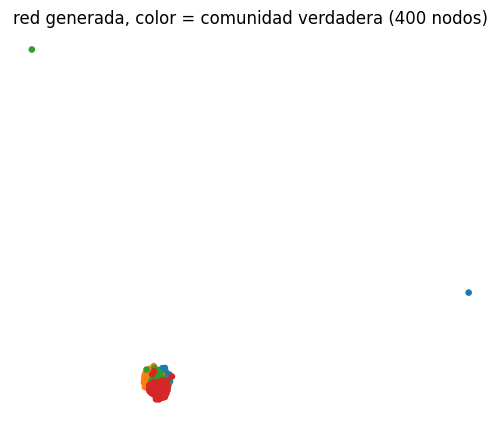

In [6]:
def make_sbm(seed, k=4, size=100, p_in=0.06, p_out=0.01, dim=16, signal=0.4):
    g = np.random.RandomState(seed)
    n = k * size
    y = np.repeat(np.arange(k), size)
    P = np.where(y[:, None] == y[None, :], p_in, p_out)
    upper = np.triu(g.rand(n, n) < P, 1)
    adj = upper | upper.T
    src, dst = np.nonzero(adj)
    centres = g.randn(k, dim)
    x = signal * centres[y] + g.randn(n, dim)
    # partición: 10 nodos etiquetados por comunidad para entrenar, 100 para validar, el resto para probar
    train, val, test = [], [], []
    for c in range(k):
        idx = g.permutation(np.where(y == c)[0])
        train += list(idx[:10]); val += list(idx[10:35]); test += list(idx[35:])
    t = lambda a: torch.tensor(np.array(a))
    return dict(x=torch.tensor(x, dtype=torch.float32), ei=torch.tensor(np.stack([src, dst])), y=t(y), train=t(train), val=t(val), test=t(test), adj=adj, n=n)

def layout(ei, n, seed=0, iters=150):
    # una pequeña disposición dirigida por fuerzas (Fruchterman-Reingold) para no necesitar biblioteca de dibujo de grafos
    g = np.random.RandomState(seed); pos = g.rand(n, 2)
    s, d = ei.numpy() if hasattr(ei, "numpy") else ei
    k = 1.0 / math.sqrt(n)
    for it in range(iters):
        diff = pos[:, None, :] - pos[None, :, :]; dist = np.linalg.norm(diff, axis=-1) + 1e-6
        disp = (diff / dist[..., None] * (k * k / dist)[..., None]).sum(1)
        dd = pos[s] - pos[d]; dl = np.linalg.norm(dd, axis=1) + 1e-6
        att = dd / dl[:, None] * (dl ** 2 / k)[:, None]
        np.add.at(disp, s, -att)
        ln = np.linalg.norm(disp, axis=1)[:, None] + 1e-6
        pos += disp / ln * np.minimum(ln, 0.1 * (1 - it / iters) + 0.005)
    return pos

D = make_sbm(0)
cls_colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
print(f"grafo SBM: {D['n']} nodos, {D['ei'].shape[1] // 2} aristas no dirigidas, grado medio {D['ei'].shape[1] / D['n']:.1f}")
same = (D["y"][D["ei"][0]] == D["y"][D["ei"][1]]).float().mean().item()
print(f"fracción de aristas que unen dos nodos de la misma comunidad (homofilia de aristas): {same:.2f}")

pos = layout(D["ei"], D["n"])
fig, ax = plt.subplots(figsize=(6.2, 5))
s, d = D["ei"].numpy()
for a, b in zip(s[::2], d[::2]):
    ax.plot(pos[[a, b], 0], pos[[a, b], 1], color="0.8", lw=0.3, zorder=1)
ax.scatter(pos[:, 0], pos[:, 1], c=[cls_colors[c] for c in D["y"].numpy()], s=14, zorder=2)
ax.set_title("red generada, color = comunidad verdadera (400 nodos)"); ax.axis("off")
plt.show()

5 grafos x 5 modelos entrenados en 77 s

modelo                           exactitud de prueba (media +- desv. típica sobre 5 grafos)
Logistic regression (features)   0.572 +- 0.079   [0.44, 0.58, 0.59, 0.68, 0.57]
MLP (ignores graph)              0.585 +- 0.064   [0.47, 0.58, 0.6, 0.65, 0.63]
GCN                              0.926 +- 0.019   [0.95, 0.93, 0.89, 0.93, 0.93]
GraphSAGE                        0.878 +- 0.029   [0.85, 0.9, 0.85, 0.92, 0.88]
GAT                              0.922 +- 0.022   [0.95, 0.93, 0.88, 0.91, 0.93]


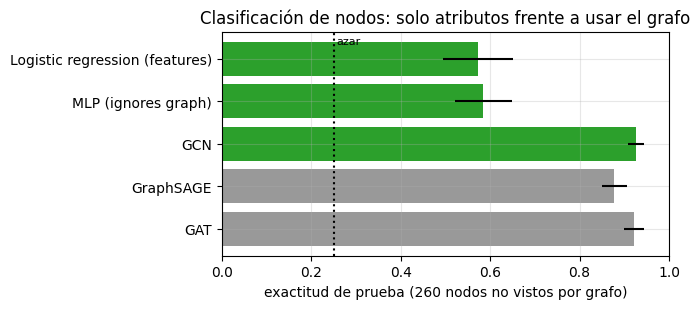

In [7]:
def train_node(model, D, epochs=120, lr=0.01, wd=5e-4):
    # entrenamiento de lote completo; la época con mejor exactitud de validación decide qué exactitud de prueba se informa
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    best_val, best_test = -1, 0
    for ep in range(epochs):
        model.train(); opt.zero_grad()
        out = model(D["x"], D["ei"])
        F.cross_entropy(out[D["train"]], D["y"][D["train"]]).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            pred = model(D["x"], D["ei"]).argmax(1)
        va = (pred[D["val"]] == D["y"][D["val"]]).float().mean().item()
        if va > best_val:
            best_val, best_test = va, (pred[D["test"]] == D["y"][D["test"]]).float().mean().item()
    return best_test

def logreg_acc(D):
    clf = LogisticRegression(max_iter=2000, C=0.5).fit(D["x"][D["train"]].numpy(), D["y"][D["train"]].numpy())
    return clf.score(D["x"][D["test"]].numpy(), D["y"][D["test"]].numpy())

layers = {"MLP (ignores graph)": NoGraphLayer, "GCN": GCNLayer, "GraphSAGE": SAGELayer, "GAT": GATLayer}
node_res = {"Logistic regression (features)": []}
node_res.update({k: [] for k in layers})
t0 = time.time()
for seed in range(5):
    D = make_sbm(100 + seed)
    node_res["Logistic regression (features)"].append(logreg_acc(D))
    for name, L in layers.items():
        torch.manual_seed(seed)
        node_res[name].append(train_node(GNN(L, 16, 32, 4, L=2), D))
print(f"5 grafos x 5 modelos entrenados en {time.time() - t0:.0f} s\n")
print(f"{'modelo':32s} exactitud de prueba (media +- desv. típica sobre 5 grafos)")
for k, v in node_res.items():
    print(f"{k:32s} {np.mean(v):.3f} +- {np.std(v):.3f}   {np.round(v, 2).tolist()}")

fig, ax = plt.subplots(figsize=(7, 3.2))
names = list(node_res); means = [np.mean(v) for v in node_res.values()]; stds = [np.std(v) for v in node_res.values()]
ax.barh(names[::-1], means[::-1], xerr=stds[::-1], color=["tab:green", "tab:green", "tab:green", "0.6", "0.6"][::-1])
ax.axvline(0.25, color="k", ls=":"); ax.text(0.255, 4.35, "azar", fontsize=8)
ax.set_xlim(0, 1); ax.set_xlabel("exactitud de prueba (260 nodos no vistos por grafo)"); ax.set_title("Clasificación de nodos: solo atributos frente a usar el grafo")
plt.tight_layout(); plt.show()

**Lectura.** Con 10 nodos etiquetados por comunidad, los modelos que solo ven los atributos apenas superan a lanzar una moneda entre 4 clases: regresión logística 0.57 y MLP 0.59 (el azar es 0.25). Cuando se permite que esos mismos atributos fluyan por las aristas, la exactitud salta a 0.93 para la GCN, 0.92 para la GAT y 0.88 para GraphSAGE. La diferencia entre los modelos que usan el grafo y los que solo usan atributos (de 0.3 a 0.35) es mucho mayor que la dispersión entre los 5 grafos (desviaciones típicas de 0.02 a 0.08), así que es real. Las diferencias *entre* las tres GNN (0.88 a 0.93) son pequeñas, y con 5 grafos la diferencia GCN frente a GAT (0.926 frente a 0.922) es ruido. GraphSAGE queda algo por detrás, lo cual es plausible pero no demostrado: promediar un nodo con sus vecinos es justo lo que premia este grafo homófilo, y GraphSAGE da un peso separado a los atributos ruidosos del propio nodo. Nótese que el MLP es tan grande como la GCN: lo que ayuda es el grafo, no el número de parámetros. El grafo también transporta la información de las etiquetas a través de los 10 nodos etiquetados de cada comunidad: los vecinos de un nodo son en su mayoría de su propia comunidad, así que unas pocas etiquetas llegan a muchos nodos.

### Cuánto ayuda el grafo depende de lo informativas que sean las aristas

La ventaja de una GNN no es constante. El paso de mensajes promedia un nodo con sus vecinos, lo cual ayuda cuando los vecinos tienden a compartir la clase del nodo (**homofilia**, como en este SBM, en las redes de citas y en las de amistad) y perjudica cuando no (**heterofilia**, como en algunas redes de fraude o bipartitas). Barremos $p_{\text{out}}$ desde 0.005 (comunidades casi desconectadas) hasta 0.06, que es igual a $p_{\text{in}}$ (las aristas no aportan ninguna información), manteniendo todo lo demás fijo, con 2 grafos por configuración, para el MLP y la GCN.

el barrido tardó 68 s
p_out   homofilia    MLP (ignores graph)                   GCN
0.005   0.82                      0.588                 0.958
0.010   0.69                      0.588                 0.952
0.020   0.52                      0.588                 0.840
0.040   0.34                      0.588                 0.477
0.060   0.26                      0.588                 0.362


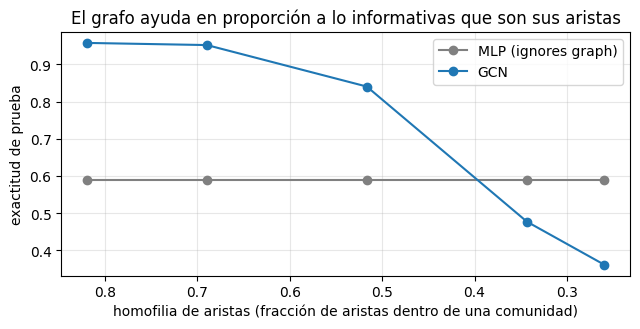

In [8]:
sweep = [0.005, 0.01, 0.02, 0.04, 0.06]
sw = {"MLP (ignores graph)": [], "GCN": []}
hom = []
t0 = time.time()
for p_out in sweep:
    accs = {k: [] for k in sw}; h = []
    for seed in range(2):
        D = make_sbm(200 + seed, p_out=p_out)
        h.append((D["y"][D["ei"][0]] == D["y"][D["ei"][1]]).float().mean().item())
        for name in sw:
            torch.manual_seed(seed)
            accs[name].append(train_node(GNN(layers[name], 16, 32, 4, L=2), D))
    for k in sw: sw[k].append(np.mean(accs[k]))
    hom.append(np.mean(h))
print(f"el barrido tardó {time.time() - t0:.0f} s")
print("p_out   homofilia   " + "  ".join(f"{k:>20s}" for k in sw))
for i, p in enumerate(sweep):
    print(f"{p:5.3f}   {hom[i]:.2f}       " + "  ".join(f"{sw[k][i]:20.3f}" for k in sw))

fig, ax = plt.subplots(figsize=(6.5, 3.4))
for k, c in zip(sw, ["0.5", "tab:blue"]):
    ax.plot(hom, sw[k], "o-", label=k, color=c)
ax.set_xlabel("homofilia de aristas (fracción de aristas dentro de una comunidad)"); ax.set_ylabel("exactitud de prueba"); ax.legend(); ax.invert_xaxis()
ax.set_title("El grafo ayuda en proporción a lo informativas que son sus aristas")
plt.tight_layout(); plt.show()

**Lectura.** La ventaja sigue a la homofilia de las aristas. Con homofilia 0.82 (pocas aristas entre comunidades) la GCN llega a 0.96 frente a 0.59 del MLP. Con 0.52 la GCN aún gana (0.84), pero con 0.34 ha caído *por debajo* del MLP (0.48 frente a 0.59), y con 0.26, donde las aristas no dicen nada sobre la comunidad (los vecinos de un nodo parecen una muestra aleatoria del grafo), baja a 0.36, muy por debajo del modelo que solo usa atributos. El paso de mensajes con un promedio fijo no es neutro: cuando los vecinos no coinciden con el nodo, mezcla los atributos propios, poco informativos, con otros no relacionados y empeora las cosas. La línea del MLP es plana porque nunca mira las aristas. Dos grafos por configuración es una muestra pequeña, así que conviene fijarse en la forma de la curva y no en el tercer decimal. En la práctica la lección es medir la homofilia antes de recurrir a una GNN, y usar capas que mantengan separado el vector propio del nodo (GraphSAGE, ejercicio 2) cuando los datos son heterófilos.

## 6. Profundidad: suavizado excesivo y aplastamiento excesivo

En una CNN, más profundo suele ser mejor (módulo 05 de Neural Networks 1001). En una GNN, ir a gran profundidad es difícil, y las razones son específicas de los grafos.

**Suavizado excesivo (over-smoothing).** Cada capa sustituye un nodo por un promedio de su vecindad. Promediar una y otra vez lleva a todos los nodos de un grafo conexo hacia el *mismo* vector, y cuando los nodos se parecen ningún clasificador puede separarlos. Oono y Suzuki (2020) demuestran que el poder expresivo de una GCN decae exponencialmente con la profundidad. Primero medimos el efecto puro de la propagación $\hat A^k X$ (sin pesos, sin entrenamiento, $k$ pasos de la regla de la GCN): la **similitud coseno media** entre los vectores de todos los pares de nodos, que es 0 para vectores no relacionados y 1 cuando todos apuntan en la misma dirección. Después entrenamos GCN de profundidad creciente y vemos qué pasa con la exactitud, con y sin **conexiones residuales** ($h' = h + \text{layer}(h)$, el truco del módulo 03 que permite a una red profunda conservar información de capas anteriores).

**Aplastamiento excesivo (over-squashing).** Incluso antes de que los nodos se vuelvan parecidos, una GNN profunda tiene un segundo problema. El campo receptivo de un nodo crece exponencialmente con el número de capas, pero toda esa información debe comprimirse en vectores de tamaño fijo a lo largo de los pocos caminos que conectan los nodos lejanos. Alon y Yahav (2021) lo llaman el cuello de botella. Lo medimos como **sensibilidad**: el tamaño de la derivada de la salida de un nodo respecto a los atributos de entrada de otro nodo, $\lVert \partial h_t / \partial x_s \rVert$ (norma del jacobiano, cuánto mueve un cambio en el nodo origen $s$ al nodo destino $t$), relativo a la sensibilidad a sus propios atributos, para una GCN inicializada al azar. Lo miramos en dos formas de grafo: un **camino** (importa la distancia) y una **estrella detrás de un puente** (muchos orígenes comparten un único canal estrecho).

k      : [0, 1, 2, 4, 8, 16, 32, 64, 128]
similitud coseno media: [-0.0, -0.0, -0.0, 0.0, 0.08, 0.94, 1.0, 1.0, 1.0]


el estudio de profundidad tardó 133 s
GCN              {1: np.float64(0.823), 2: np.float64(0.919), 4: np.float64(0.74), 8: np.float64(0.242), 16: np.float64(0.223)}
GCN + residual   {1: np.float64(0.823), 2: np.float64(0.91), 4: np.float64(0.902), 8: np.float64(0.915), 16: np.float64(0.913)}


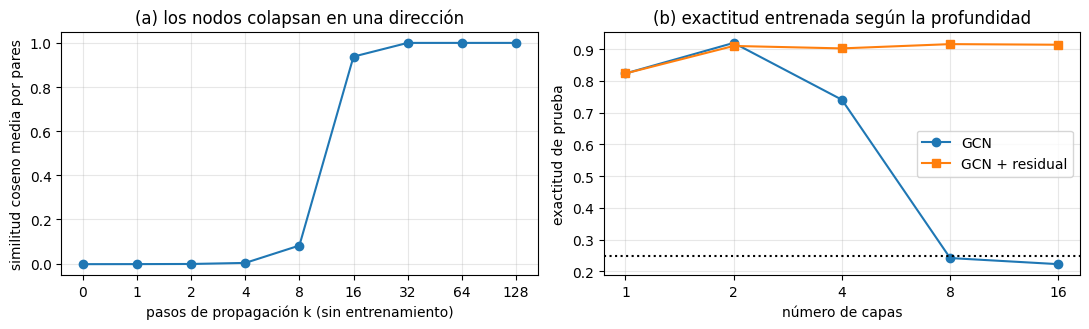

In [9]:
# (a) suavizado excesivo de la propagación pura, sin entrenamiento: similitud coseno media por pares de los vectores de nodos tras k pasos de A_hat
D = make_sbm(300)
n_, ei_ = D["n"], D["ei"]
Ah = torch.zeros(n_, n_); Ah[ei_[0], ei_[1]] = 1; Ah += torch.eye(n_)
dv = Ah.sum(1).rsqrt(); Ah = dv[:, None] * Ah * dv[None, :]
def mean_cos(H):
    Hn = F.normalize(H, dim=1); S = Hn @ Hn.T
    return ((S.sum() - n_) / (n_ * (n_ - 1))).item()
H = D["x"] - D["x"].mean(0)                          # atributos centrados, de modo que similitud 0 significa "no relacionados"
ks = [0, 1, 2, 4, 8, 16, 32, 64, 128]
cos_k = []
Hk = H.clone(); step = 0
for k in ks:
    while step < k: Hk = Ah @ Hk; step += 1
    cos_k.append(mean_cos(Hk))
print("k      :", ks)
print("similitud coseno media:", [round(c, 2) for c in cos_k])

# (b) GCN entrenadas con profundidad creciente, con y sin conexiones residuales (2 grafos cada una)
depths = [1, 2, 4, 8, 16]
dep = {"GCN": [], "GCN + residual": []}
t0 = time.time()
for L in depths:
    a, b = [], []
    for seed in range(2):
        D = make_sbm(400 + seed)
        torch.manual_seed(seed); a.append(train_node(GNN(GCNLayer, 16, 32, 4, L=L, dropout=0.2), D, epochs=80))
        torch.manual_seed(seed); b.append(train_node(GNN(GCNLayer, 16, 32, 4, L=L, dropout=0.2, residual=True), D, epochs=80))
    dep["GCN"].append(np.mean(a)); dep["GCN + residual"].append(np.mean(b))
print(f"el estudio de profundidad tardó {time.time() - t0:.0f} s")
for k, v in dep.items():
    print(f"{k:16s}", {L: round(x, 3) for L, x in zip(depths, v)})

fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
axs[0].plot(range(len(ks)), cos_k, "o-"); axs[0].set_xticks(range(len(ks))); axs[0].set_xticklabels(ks)
axs[0].set_xlabel("pasos de propagación k (sin entrenamiento)"); axs[0].set_ylabel("similitud coseno media por pares"); axs[0].set_title("(a) los nodos colapsan en una dirección")
axs[1].plot(range(len(depths)), dep["GCN"], "o-", label="GCN"); axs[1].plot(range(len(depths)), dep["GCN + residual"], "s-", label="GCN + residual")
axs[1].set_xticks(range(len(depths))); axs[1].set_xticklabels(depths); axs[1].axhline(0.25, color="k", ls=":")
axs[1].set_xlabel("número de capas"); axs[1].set_ylabel("exactitud de prueba"); axs[1].legend(); axs[1].set_title("(b) exactitud entrenada según la profundidad")
plt.tight_layout(); plt.show()

**Lectura.** Panel (a): la propagación sola, sin aprendizaje, ya muestra el efecto. La similitud coseno media es de aproximadamente 0 para los atributos originales y sigue cerca de 0 durante los primeros pasos, luego sube a 0.08 tras 8 pasos, 0.94 tras 16 y 1.00 a partir de 32 pasos: tras suficiente promediado todos los nodos apuntan en la misma dirección y la información que los distinguía se ha perdido. Panel (b): la GCN entrenada es mejor con 2 capas (0.92), y se degrada a 0.74 con 4 y al nivel del azar (0.22 a 0.24) con 8 y 16 capas. Hay que ser honestos: este colapso mezcla el suavizado excesivo con una simple dificultad de **optimización** (las pilas profundas sin conexiones de salto son difíciles de entrenar, módulo 03 de Neural Networks 1001), y nuestro experimento no separa ambas cosas. Lo que sí muestra es que la variante residual, que tiene las mismas capas más $h' = h + \text{layer}(h)$, se mantiene en 0.90 a 0.92 de 4 a 16 capas: la conexión de salto permite que la información de las primeras capas llegue al clasificador. No supera a la GCN de 2 capas (0.92 frente a 0.91 a 0.92), así que la profundidad no aportó nada en esta tarea fácil, y cada configuración usa solo 2 grafos.

grafo camino, 10 capas: influencia relativa a distancia r = 1..10:
['1.0e+00', '8.4e-01', '5.4e-01', '3.1e-01', '1.6e-01', '7.6e-02', '2.4e-02', '7.2e-03', '1.2e-03', '1.4e-04']


grafo con puente, 2 capas: influencia relativa de una hoja sobre el destino, con k hojas tras el puente:
{1: 0.465, 2: 0.342, 4: 0.266, 8: 0.16, 16: 0.098, 32: 0.056, 64: 0.029}


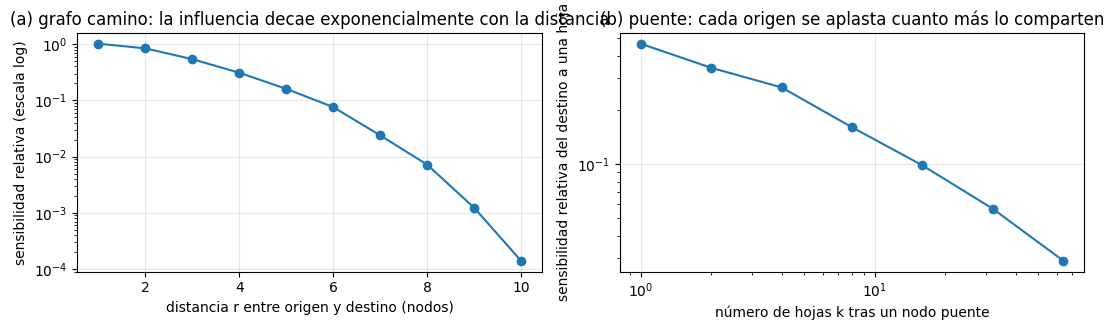

In [10]:
def sensitivity(ei, n, s, t, L, hid=16, seeds=8):
    # |d h_t / d x_s| (norma de Frobenius del jacobiano de la salida del nodo t respecto a la entrada del nodo s) dividida por lo mismo para la propia entrada de t,
    # para una GCN inicializada al azar con L capas; el cociente elimina el efecto de la escala de los pesos.
    vals = []
    for sd in range(seeds):
        torch.manual_seed(sd)
        net = GNN(GCNLayer, 4, hid, hid, L=L, dropout=0.0)
        x = torch.randn(n, 4)
        def f(xx): return net(xx, ei)[t]
        J = torch.autograd.functional.jacobian(f, x)          # (hid, n, 4)
        vals.append((J[:, s].norm() / J[:, t].norm()).item())
    return float(np.mean(vals))

# grafo camino de 14 nodos, destino = nodo 0, 10 capas: influencia del nodo a distancia r
npath = 14
pe = torch.tensor([[i for i in range(npath - 1)] + [i + 1 for i in range(npath - 1)], [i + 1 for i in range(npath - 1)] + [i for i in range(npath - 1)]])
path_sens = [sensitivity(pe, npath, r, 0, L=10) for r in range(1, 11)]
print("grafo camino, 10 capas: influencia relativa a distancia r = 1..10:")
print([f"{v:.1e}" for v in path_sens])

# estrella detrás de un puente: destino t - puente b - k hojas; 2 capas; influencia de UNA hoja sobre t
def bridge_graph(k):
    nodes = k + 2; t, b = 0, 1
    edges = [(t, b)] + [(b, 2 + i) for i in range(k)]
    return torch.tensor([[a for a, c in edges] + [c for a, c in edges], [c for a, c in edges] + [a for a, c in edges]]), nodes
ks_leaf = [1, 2, 4, 8, 16, 32, 64]
leaf_sens = []
for k in ks_leaf:
    e, nn_ = bridge_graph(k)
    leaf_sens.append(sensitivity(e, nn_, 2, 0, L=2))
print("grafo con puente, 2 capas: influencia relativa de una hoja sobre el destino, con k hojas tras el puente:")
print({k: round(v, 3) for k, v in zip(ks_leaf, leaf_sens)})

fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
axs[0].semilogy(range(1, 11), path_sens, "o-"); axs[0].set_xlabel("distancia r entre origen y destino (nodos)"); axs[0].set_ylabel("sensibilidad relativa (escala log)")
axs[0].set_title("(a) grafo camino: la influencia decae exponencialmente con la distancia")
axs[1].loglog(ks_leaf, leaf_sens, "o-"); axs[1].set_xlabel("número de hojas k tras un nodo puente"); axs[1].set_ylabel("sensibilidad relativa del destino a una hoja")
axs[1].set_title("(b) puente: cada origen se aplasta cuanto más lo comparten")
plt.tight_layout(); plt.show()

**Lectura.** Panel (a): en un camino, la influencia de un nodo sobre el destino cae de 1.0 a distancia 1 a 0.31 a distancia 4, 0.024 a distancia 7 y 0.00014 a distancia 10, aproximadamente un orden de magnitud cada tres saltos, aunque la red es lo bastante profunda para alcanzarlos a todos. Un origen a 10 saltos prácticamente no tiene voz. Panel (b): cuando muchos orígenes comparten un nodo puente, la influencia de una sola hoja disminuye al añadir más hojas (0.47 con una hoja, 0.16 con 8, 0.03 con 64), aproximadamente como uno partido por la raíz cuadrada del número de hojas (multiplicar por 64 la divide por unas 16), porque el vector de tamaño fijo del puente tiene que transportarlas todas. Este es el cuello de botella del aplastamiento excesivo, medido aquí en redes inicializadas al azar (promedio de 8 inicializaciones) para mostrar que proviene de la *estructura* y no del entrenamiento. No entrenamos un modelo en una tarea que necesite la información lejana, así que esto es una medida de sensibilidad, no de exactitud; Alon y Yahav (2021) presentan los experimentos entrenados.

**Qué se hace al respecto** (no medido aquí): mantener la red poco profunda y ensancharla en su lugar (lo normal son de 2 a 4 capas), añadir conexiones residuales o conexiones de "jumping knowledge" que leen todas las capas, normalizar entre capas, **recablear** el grafo para añadir atajos a través de los cuellos de botella (Topping et al., 2022), o dejar que los nodos atiendan a nodos lejanos con una capa al estilo transformer (transformers de grafos), que es otra vez la idea de la sección 4 del GAT sobre un grafo completo.

## 7. Tareas a nivel de grafo: moléculas y la lectura

Ahora la unidad de predicción es un *grafo entero*. Un candidato a fármaco es un grafo molecular (los átomos son nodos, los enlaces son aristas) y queremos un número para él: ¿es tóxico?, ¿cómo de bien se disuelve?, ¿mata a una bacteria? El único ingrediente nuevo es la **lectura** (readout): tras $L$ capas de paso de mensajes, se colapsan los vectores de los nodos de cada grafo en un vector de grafo con una función invariante a las permutaciones y se pasa a un clasificador ordinario,

$$h_G = \bigoplus_{i \in V} h_i^{(L)}, \qquad \hat y = \mathrm{MLP}(h_G), \qquad \bigoplus \in \{\text{suma}, \text{media}, \text{máximo}\}.$$

**Datos.** **MUTAG** tiene 188 moléculas pequeñas (unos 18 átomos y 20 enlaces cada una) que son compuestos nitroaromáticos, etiquetados según tengan o no un efecto mutagénico sobre una bacteria (*Salmonella typhimurium*): 125 son mutagénicos y 63 no (Debnath et al., 1991). Es uno de los conjuntos de referencia de la colección de la TU Dortmund (Morris et al., 2020, https://chrsmrrs.github.io/datasets/); los archivos son la distribución estándar de esa colección, publicada para uso en investigación, y los compuestos originales provienen del artículo de 1991. Descargamos el archivo de 24 kB una vez en `data/` y usamos el tipo de átomo (7 elementos) como atributo one-hot del nodo. Si no hay acceso a la red, el código recurre a grafos generados parecidos a moléculas con un motivo plantado para que el notebook siga funcionando; el mensaje impreso indica cuál se está usando.

**Protocolo.** 188 grafos es un conjunto pequeño, así que usamos validación cruzada estratificada de 5 particiones (entrenar con 4 quintos, probar con el quinto restante, rotar) y damos la media y la desviación típica de las 5 exactitudes de prueba. Cada modelo se entrena durante 100 épocas fijas, así que no hay fuga desde la partición de prueba hacia la elección de la época.

**Modelos.** Línea base de atributos: regresión logística sobre la **bolsa de átomos** (cuántos átomos de cada elemento, más el número de átomos). Ignora el grafo: la misma red con `NoGraphLayer` y una lectura por suma (un "deep set": cada átomo se procesa por separado y luego se suman). GNN: GCN con lecturas de media, suma y máximo, GraphSAGE, GAT y GIN. Por último, un **control de estructura**: una GCN en la que sustituimos los enlaces de cada molécula por el mismo número de enlaces *aleatorios* entre sus átomos, lo que conserva los átomos y el tamaño del grafo pero destruye la química.

conjunto de datos: MUTAG (TU Dortmund collection): 188 grafos, 3371 átomos, 3721 enlaces, átomos por grafo 17.9 (mín 10, máx 28), balance de clases 0.66 positivo
tipos de átomo (C, N, O, F, I, Cl, Br), recuentos totales: [2395, 345, 593, 12, 1, 23, 2]


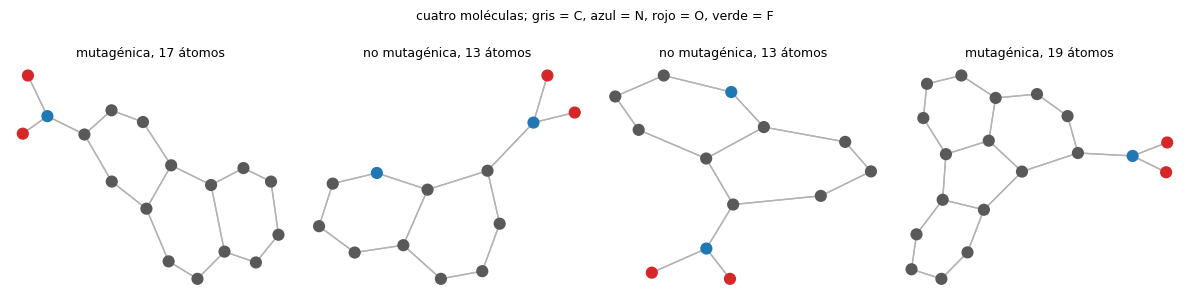

máx |diferencia de salida| tras renumerar los átomos: 1.4901161193847656e-08


In [11]:
CACHE = "data/MUTAG"
URL = "https://www.chrsmrrs.com/graphkerneldatasets/MUTAG.zip"

def load_mutag():
    if not os.path.exists(os.path.join(CACHE, "MUTAG_A.txt")):
        os.makedirs("data", exist_ok=True)
        raw = urllib.request.urlopen(urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"}), timeout=30).read()
        zipfile.ZipFile(io.BytesIO(raw)).extractall("data")
    rd = lambda f: np.loadtxt(os.path.join(CACHE, f"MUTAG_{f}.txt"), delimiter=",", dtype=int)
    A_ = rd("A") - 1; gid = rd("graph_indicator") - 1; nl = rd("node_labels"); gl = rd("graph_labels")
    return A_.T, gid, np.eye(nl.max() + 1)[nl].astype(np.float32), (gl == 1).astype(int)

def fake_molecules(num=188, seed=0):
    # alternativa: "moléculas" aleatorias en forma de árbol con 7 elementos; etiqueta = contiene un átomo de N enlazado a dos de O (un motivo tipo nitro)
    g = np.random.RandomState(seed); E, gid, X, y, off = [], [], [], [], 0
    for i in range(num):
        m = g.randint(10, 28); types = g.choice(7, m, p=[.6, .1, .1, .05, .05, .05, .05]); edges = [(j, g.randint(0, j)) for j in range(1, m)]
        if i % 2 == 0:
            a = g.randint(0, m - 2); types[a], types[a + 1], types[(a + 2) % m] = 1, 2, 2; edges += [(a, a + 1), (a, (a + 2) % m)]
        lab = int(any(types[a] == 1 and sum(types[b] == 2 for p, q in edges for b in ([q] if p == a else [p] if q == a else [])) >= 2 for a in range(m)))
        E += [(a + off, b + off) for a, b in edges] + [(b + off, a + off) for a, b in edges]; gid += [i] * m; X += list(np.eye(7)[types]); y.append(lab); off += m
    return np.array(E).T, np.array(gid), np.array(X, dtype=np.float32), np.array(y)

try:
    E_all, gid, X_all, Y = load_mutag(); source = "MUTAG (TU Dortmund collection)"
except Exception as ex:
    print("falló la descarga (", type(ex).__name__, "), se usan en su lugar grafos generados parecidos a moléculas")
    E_all, gid, X_all, Y = fake_molecules(); source = "generated molecule-like graphs"
Ng = len(Y)
sizes = np.bincount(gid)
print(f"conjunto de datos: {source}: {Ng} grafos, {X_all.shape[0]} átomos, {E_all.shape[1] // 2} enlaces, "
      f"átomos por grafo {sizes.mean():.1f} (mín {sizes.min()}, máx {sizes.max()}), balance de clases {Y.mean():.2f} positivo")
print("tipos de átomo (C, N, O, F, I, Cl, Br), recuentos totales:", X_all.sum(0).astype(int).tolist())

def collate(ids, shuffle_edges=None):
    # construye un gran grafo diagonal por bloques a partir de un subconjunto de grafos
    ids = np.asarray(ids); node_mask = np.isin(gid, ids)
    new_id = -np.ones(len(gid), dtype=int); new_id[node_mask] = np.arange(node_mask.sum())
    remap = {g: i for i, g in enumerate(ids)}
    batch = torch.tensor([remap[g] for g in gid[node_mask]])
    em = node_mask[E_all[0]]; e = new_id[E_all[:, em]]
    if shuffle_edges is not None:
        # control: mismo número de enlaces por molécula, pero entre pares aleatorios de sus átomos
        g_ = np.random.RandomState(shuffle_edges); starts = np.concatenate([[0], np.cumsum(np.bincount(batch.numpy()))])
        cnt = np.bincount(batch.numpy()[e[0]], minlength=len(ids)) // 2; es = []
        for gi in range(len(ids)):
            nn_ = starts[gi + 1] - starts[gi]; a = g_.randint(0, nn_, cnt[gi]); b = (a + g_.randint(1, nn_, cnt[gi])) % nn_
            es += [(starts[gi] + a, starts[gi] + b), (starts[gi] + b, starts[gi] + a)]
        e = np.concatenate([np.array([p[0], p[1]]) for p in es], axis=1)
    return torch.tensor(X_all[node_mask]), torch.tensor(e), batch, torch.tensor(Y[ids]), len(ids)

# dibujamos unas cuantas moléculas (disposición por fuerzas), color = elemento
elem_col = ["0.35", "tab:blue", "tab:red", "tab:green", "tab:purple", "tab:olive", "tab:brown"]
fig, axs = plt.subplots(1, 4, figsize=(12, 3))
for ax, gi in zip(axs, [0, 1, 2, 3]):
    x_, e_, b_, y_, _ = collate([gi]); p_ = layout(e_, x_.shape[0], seed=gi, iters=200)
    for a, b in zip(*e_.numpy()): ax.plot(p_[[a, b], 0], p_[[a, b], 1], color="0.7", lw=1, zorder=1)
    ax.scatter(p_[:, 0], p_[:, 1], c=[elem_col[c] for c in x_.argmax(1).numpy()], s=60, zorder=2)
    ax.set_title(("mutagénica" if y_.item() else "no mutagénica") + f", {x_.shape[0]} átomos", fontsize=9); ax.axis("off")
plt.suptitle("cuatro moléculas; gris = C, azul = N, rojo = O, verde = F", fontsize=9); plt.tight_layout(); plt.show()

# la prueba de permutación en una red sin entrenar: renumerar los átomos de una molécula no cambia la salida
x_, e_, b_, y_, ng_ = collate([5])
torch.manual_seed(0); net = GNN(GCNLayer, 7, 32, 2, L=3, readout="sum").eval()
p_ = torch.randperm(x_.shape[0]); inv_ = torch.argsort(p_)
with torch.no_grad():
    o1 = net(x_, e_, b_, ng_); o2 = net(x_[p_], inv_[e_], b_, ng_)
print("máx |diferencia de salida| tras renumerar los átomos:", float((o1 - o2).abs().max()))

validación cruzada de 5 particiones de 9 modelos: 198 s

modelo                                 exactitud (media +- desv. típica sobre 5 particiones)
Logistic regression (bag of atoms)     0.862 +- 0.038
Ignores graph (deep set, sum)          0.851 +- 0.031
GCN, mean readout                      0.745 +- 0.070
GCN, sum readout                       0.819 +- 0.029
GCN, max readout                       0.771 +- 0.075
GraphSAGE, mean readout                0.739 +- 0.046
GAT, mean readout                      0.750 +- 0.042
GIN, sum readout                       0.851 +- 0.048
GCN sum, RANDOM bonds (control)        0.787 +- 0.069

tasa de la clase mayoritaria (predecir siempre 'mutagénica'): 0.665


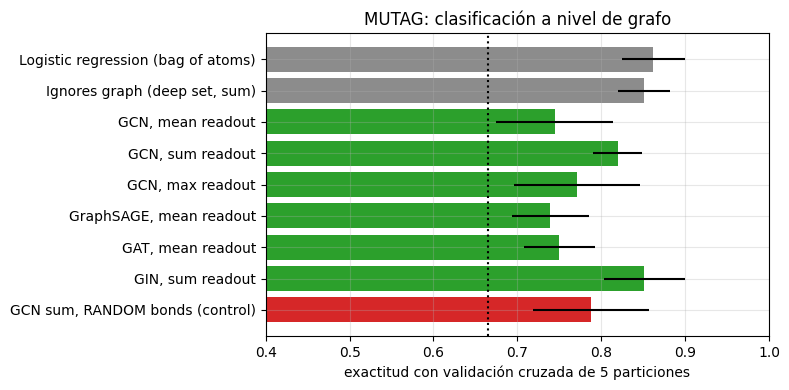

In [12]:
def train_graph(model, train_data, test_data, epochs=100, lr=0.01, wd=1e-4):
    Xt, Et, Bt, Yt, Nt = train_data; Xe, Ee, Be, Ye, Ne = test_data
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    for ep in range(epochs):
        model.train(); opt.zero_grad()
        F.cross_entropy(model(Xt, Et, Bt, Nt), Yt).backward(); opt.step()
    model.eval()
    with torch.no_grad():
        return (model(Xe, Ee, Be, Ne).argmax(1) == Ye).float().mean().item()

def bag_of_atoms(ids):
    return np.array([np.append(X_all[gid == g].sum(0), (gid == g).sum()) for g in ids])

configs = {
    "Logistic regression (bag of atoms)": None,
    "Ignores graph (deep set, sum)": (NoGraphLayer, "sum", None),
    "GCN, mean readout": (GCNLayer, "mean", None),
    "GCN, sum readout": (GCNLayer, "sum", None),
    "GCN, max readout": (GCNLayer, "max", None),
    "GraphSAGE, mean readout": (SAGELayer, "mean", None),
    "GAT, mean readout": (GATLayer, "mean", None),
    "GIN, sum readout": (GINLayer, "sum", None),
    "GCN sum, RANDOM bonds (control)": (GCNLayer, "sum", 7),
}
cv_res = {k: [] for k in configs}
skf = StratifiedKFold(5, shuffle=True, random_state=0)
t0 = time.time()
for fold, (tr, te) in enumerate(skf.split(np.zeros(Ng), Y)):
    data = {None: (collate(tr), collate(te)), 7: (collate(tr, 7), collate(te, 7))}      # construimos una sola vez los tensores de cada partición
    for name, cfg in configs.items():
        if cfg is None:
            clf = LogisticRegression(max_iter=5000, C=1.0).fit(bag_of_atoms(tr), Y[tr])
            cv_res[name].append(clf.score(bag_of_atoms(te), Y[te]))
        else:
            torch.manual_seed(fold)
            m = GNN(cfg[0], 7, 32, 2, L=3, readout=cfg[1], dropout=0.0)
            cv_res[name].append(train_graph(m, *data[cfg[2]]))
print(f"validación cruzada de 5 particiones de {len(configs)} modelos: {time.time() - t0:.0f} s\n")
print(f"{'modelo':38s} exactitud (media +- desv. típica sobre 5 particiones)")
for k, v in cv_res.items():
    print(f"{k:38s} {np.mean(v):.3f} +- {np.std(v):.3f}")
print(f"\ntasa de la clase mayoritaria (predecir siempre 'mutagénica'): {max(Y.mean(), 1 - Y.mean()):.3f}")

fig, ax = plt.subplots(figsize=(8, 4))
names = list(cv_res); means = [np.mean(v) for v in cv_res.values()]; stds = [np.std(v) for v in cv_res.values()]
cols = ["0.55", "0.55"] + ["tab:green"] * 6 + ["tab:red"]
ax.barh(names[::-1], means[::-1], xerr=stds[::-1], color=cols[::-1])
ax.axvline(max(Y.mean(), 1 - Y.mean()), color="k", ls=":"); ax.set_xlim(0.4, 1.0)
ax.set_xlabel("exactitud con validación cruzada de 5 particiones"); ax.set_title("MUTAG: clasificación a nivel de grafo")
plt.tight_layout(); plt.show()

**Lectura.** Aquí el resultado honesto es **negativo para el grafo**. El modelo más simple, la regresión logística sobre el recuento de cada elemento, obtiene 0.86, y el deep set que procesa cada átomo por separado y los suma obtiene 0.85. Ninguna GNN los supera: GIN con lectura por suma es la más cercana (0.85), la GCN con lectura por suma obtiene 0.83, y los modelos con lectura por media (GCN 0.75, GraphSAGE 0.74, GAT 0.76) y por máximo (0.77) quedan claramente por debajo. Con 188 moléculas y 5 particiones las desviaciones típicas entre particiones son de 0.03 a 0.08, así que las diferencias inferiores a unos 0.04 (línea base frente a GIN, GCN con suma frente a la línea base) no se distinguen del ruido, mientras que la brecha de 0.1 con los modelos de lectura por media probablemente es real. De aquí salen dos lecciones. Primero, la lectura importa: la **suma** conserva el *número* de átomos de nitrógeno y oxígeno (la mutagenicidad de estos compuestos nitro está ligada a tales grupos), que una media descarta; es el argumento de Xu et al. (2019) a favor de las capas basadas en sumas. Segundo, el control de enlaces aleatorios (0.79) es casi tan bueno como la GCN con los enlaces verdaderos y la misma lectura (0.83) dado el ruido, lo que indica que en este conjunto pequeño y con un presupuesto de 100 épocas las redes usan sobre todo *qué átomos hay* y no *cómo están enlazados*. Eso no significa que la estructura química sea irrelevante en general: los resultados publicados en MUTAG con modelos ajustados y atributos de aristas (tipo de enlace) son más altos, y se sabe que el conjunto es pequeño y está casi saturado por descriptores simples. Fijamos el presupuesto de entrenamiento, no ajustamos ningún hiperparámetro y usamos una sola división en particiones, así que conviene tratar el orden de las variantes de GNN como provisional (ejercicio 6).

**Dónde se diferencia el juguete de los sistemas reales.** Nuestros grafos tienen cientos de nodos o unos 18 átomos, las capas son de lote completo en una CPU, y se ignoran los *tipos* de enlace (simple, doble, aromático) y la geometría 3D de las moléculas. Los modelos de descubrimiento de fármacos en producción usan millones de moléculas, atributos de aristas, coordenadas 3D y muchas capas de paso de mensajes con GPU, y los recomendadores a escala web muestrean vecindades (la idea de GraphSAGE) porque el grafo no cabe en memoria.

## 8. Dónde se usan las GNN en producción

La misma capa, aplicada a grafos muy distintos. En todos estos casos los datos tienen un grafo natural que un MLP o una CNN corrientes no pueden respetar.

| Dominio | El grafo | Qué hace la GNN | Referencia |
|---|---|---|---|
| **Clima** | la superficie de la Tierra como una malla de aproximadamente un millón de puntos, con aristas entre puntos cercanos | **GraphCast** predice el estado global de la atmósfera a 10 días en menos de un minuto, y superó al principal pronóstico numérico operativo en la mayoría de los objetivos de verificación | Lam et al. (2023), Science |
| **Tráfico y rutas** | tramos de carretera como nodos, conectados donde se encuentran | el tiempo estimado de llegada en Google Maps sale de una GNN sobre "supertramos" de la red viaria, con grandes reducciones de estimaciones malas en varias ciudades | Derrow-Pinion et al. (2021) |
| **Descubrimiento de fármacos** | átomos y enlaces de una molécula | una red de paso de mensajes sobre moléculas encontró la halicina, un antibiótico nuevo que después se confirmó en el laboratorio | Stokes et al. (2020), Cell |
| **Redes eléctricas** | barras (subestaciones) como nodos, líneas de transmisión como aristas | una GNN aprende a resolver las ecuaciones del flujo de potencia como sustituto rápido del solucionador iterativo | Donon et al. (2020) |
| **Recomendación** | usuarios y elementos, unidos por clics y guardados | PinSage, una red al estilo GraphSAGE muestreada sobre un grafo de 3000 millones de nodos, alimenta las recomendaciones de pines relacionados en Pinterest | Ying et al. (2018) |

Otros lugares donde mirar: capas GNN dentro de modelos de estructura de proteínas y de dinámica molecular, detección de fraude en grafos de transacciones, reconstrucción de eventos de física de partículas, diseño de chips y grafos de conocimiento. Un patrón recurrente es que la GNN es una *aproximación rápida aprendida* de algo lento (una simulación numérica, un solucionador físico, un experimento de laboratorio) o una forma de incorporar estructura relacional a un recomendador. El módulo 09 de este curso examina con más detalle la primera idea (aprendizaje automático científico).

## 9. Ideas clave, ejercicios, referencias

## Ideas clave

* Un grafo no tiene cuadrícula ni orden, así que un modelo debe ser **equivariante a las permutaciones** (salidas por nodo) o **invariante** (una salida por grafo). Agregar a los vecinos con una suma, una media o un máximo lo da gratis, y lo verificamos numéricamente.
* El **paso de mensajes** (mensaje, agregación, actualización) es una plantilla. GCN usa un promedio fijo normalizado por el grado, GraphSAGE separa un nodo de sus vecinos, GAT aprende los pesos de los vecinos con atención y GIN usa una suma. Un GAT con una máscara de unos es la atención del transformer del módulo 09 de Neural Networks 1001.
* En una red con comunidades conocidas, el grafo vale tanto como la **homofilia** de sus aristas: véanse las cifras medidas en la sección 5. Cuando las aristas no llevan señal, una GNN no tiene ventaja y puede perder frente a un modelo que ignora el grafo.
* La profundidad está limitada por el **suavizado excesivo** (los nodos se vuelven parecidos) y el **aplastamiento excesivo** (demasiada información por un canal demasiado estrecho). Medimos ambos. Las redes poco profundas, las conexiones residuales y el recableado son los remedios habituales.
* En las tareas a nivel de grafo, una **lectura** agrupa los nodos. La elección (suma, media, máximo) importa, y en un conjunto pequeño como MUTAG las diferencias de unos pocos puntos están dentro del ruido de la validación cruzada.
* Compara siempre con un modelo que ignore el grafo y con una línea base de atributos sencilla. Si la GNN no los supera, el grafo no está aportando información.

## Ejercicios

1. En la sección 5, cambia `signal` de 0.4 a 0.1 y a 1.0. ¿Cómo responden el MLP y la GCN? ¿Dónde se cierra la brecha entre ellos?
2. Añade una configuración **heterófila**: haz que los nodos se enlacen *entre* comunidades más que dentro (por ejemplo $p_{\text{in}} = 0.01$ y $p_{\text{out}} = 0.05$). ¿Qué modelo se degrada más, y resiste mejor GraphSAGE (que mantiene separado el vector propio del nodo) que la GCN?
3. Dibuja los pesos de atención `last_alpha` de la primera `GATLayer` para un nodo del SBM, separados según el vecino esté o no en la misma comunidad. ¿Aprende la GAT a escuchar más a los vecinos de su comunidad?
4. En la sección 6, repite el estudio de profundidad con GraphSAGE y con GAT. ¿Suavizan en exceso tan rápido como la GCN? Prueba 16 capas con dropout 0 y decaimiento de pesos 0.
5. En la sección 7 añade el **tipo de enlace** (el archivo `MUTAG_edge_labels.txt`) como atributo de arista: multiplica cada mensaje por un embedding aprendido del tipo de enlace. ¿Se mueve la exactitud más allá del ruido entre particiones?
6. Repite la validación cruzada de MUTAG con 5 mezclas distintas de las particiones (`random_state`) y mira la dispersión de las medias. ¿Cuáles de las diferencias que viste en la tabla sobreviven?
7. Sustituye la lectura por media por una lectura con atención: una puntuación aprendida por nodo, un softmax sobre los nodos de cada grafo, una suma ponderada. Compara.
8. Implementa el **muestreo** de vecinos para GraphSAGE: conserva como máximo 5 aristas de entrada aleatorias por nodo en cada paso de entrenamiento, y prueba con todas. ¿Cuánta exactitud pierdes, y cuánto más rápido es un paso en el grafo aleatorio de 2000 nodos y 20000 aristas de la sección 3?

## Referencias

* Gilmer, J., Schoenholz, S. S., Riley, P. F., Vinyals, O. and Dahl, G. E. (2017). Neural message passing for quantum chemistry. ICML 2017. arXiv:1704.01212: https://arxiv.org/abs/1704.01212
* Kipf, T. N. and Welling, M. (2017). Semi-supervised classification with graph convolutional networks. ICLR 2017. arXiv:1609.02907: https://arxiv.org/abs/1609.02907
* Hamilton, W. L., Ying, R. and Leskovec, J. (2017). Inductive representation learning on large graphs (GraphSAGE). NeurIPS 2017. arXiv:1706.02216: https://arxiv.org/abs/1706.02216
* Velickovic, P., Cucurull, G., Casanova, A., Romero, A., Lio, P. and Bengio, Y. (2018). Graph attention networks. ICLR 2018. arXiv:1710.10903: https://arxiv.org/abs/1710.10903
* Xu, K., Hu, W., Leskovec, J. and Jegelka, S. (2019). How powerful are graph neural networks? (GIN). ICLR 2019. arXiv:1810.00826: https://arxiv.org/abs/1810.00826
* Bronstein, M. M., Bruna, J., Cohen, T. and Velickovic, P. (2021). Geometric deep learning: grids, groups, graphs, geodesics, and gauges. arXiv:2104.13478: https://arxiv.org/abs/2104.13478
* Oono, K. and Suzuki, T. (2020). Graph neural networks exponentially lose expressive power for node classification. ICLR 2020. arXiv:1905.10947: https://arxiv.org/abs/1905.10947
* Alon, U. and Yahav, E. (2021). On the bottleneck of graph neural networks and its practical implications. ICLR 2021. arXiv:2006.05205: https://arxiv.org/abs/2006.05205
* Topping, J., Di Giovanni, F., Chamberlain, B. P., Dong, X. and Bronstein, M. M. (2022). Understanding over-squashing and bottlenecks on graphs via curvature. ICLR 2022. arXiv:2111.14522: https://arxiv.org/abs/2111.14522
* Morris, C., Kriege, N. M., Bause, F., Kersting, K., Mutzel, P. and Neumann, M. (2020). TUDataset: a collection of benchmark datasets for learning with graphs. arXiv:2007.08663: https://arxiv.org/abs/2007.08663 (datos: https://chrsmrrs.github.io/datasets/)
* Debnath, A. K., Lopez de Compadre, R. L., Debnath, G., Shusterman, A. J. and Hansch, C. (1991). Structure-activity relationship of mutagenic aromatic and heteroaromatic nitro compounds (MUTAG). *Journal of Medicinal Chemistry* 34(2), 786-797: https://doi.org/10.1021/jm00106a046
* Lam, R. et al. (2023). Learning skillful medium-range global weather forecasting (GraphCast). *Science* 382(6677), 1416-1421: https://doi.org/10.1126/science.adi2336
* Derrow-Pinion, A. et al. (2021). ETA prediction with graph neural networks in Google Maps. CIKM 2021. arXiv:2108.11482: https://arxiv.org/abs/2108.11482
* Stokes, J. M. et al. (2020). A deep learning approach to antibiotic discovery. *Cell* 180(4), 688-702: https://doi.org/10.1016/j.cell.2020.01.021
* Donon, B., Clément, R., Donnot, B., Marot, A., Guyon, I. and Schoenauer, M. (2020). Neural networks for power flow: graph neural solver. *Electric Power Systems Research* 189, 106547: https://doi.org/10.1016/j.epsr.2020.106547
* Ying, R., He, R., Chen, K., Eksombatchai, P., Hamilton, W. L. and Leskovec, J. (2018). Graph convolutional neural networks for web-scale recommender systems (PinSage). KDD 2018. arXiv:1806.01973: https://arxiv.org/abs/1806.01973

In [13]:
print(f"tiempo total de ejecución del notebook: {time.time() - T_START:.0f} s")

tiempo total de ejecución del notebook: 506 s
